# 03 · Alerts, explanations and crisis replays

An *event* is a market reaching ALPS Alert or Crisis (ALPS ≥ 1) at t+h. Three routes are compared, each with thresholds tuned on earlier years only: the interval route (probability that the forecast clears the Alert threshold), a class-weighted LightGBM phase classifier, and a logistic stack of both with today's ALPS. *Persistence* carries today's phase forward; it cannot see a new alert coming (onset recall 0).

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
PROC, STORE, FIG = ROOT / "data/processed", ROOT / "data/store", ROOT / "reports/figures"
FIG.mkdir(parents=True, exist_ok=True)
PHASE_COLORS = {"Normal": "#2e7d32", "Stress": "#f2b705", "Alert": "#e8590c", "Crisis": "#c92a2a"}
DROUGHTS = [("2010-10-01", "2011-09-01"), ("2016-10-01", "2017-08-01"), ("2021-10-01", "2023-03-01")]
def shade(ax):
    for a, b in DROUGHTS:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="#c92a2a", alpha=0.07, lw=0)
metrics = json.loads((STORE / "metrics.json").read_text())


In [2]:
al = pd.DataFrame(metrics["alerts"])
print("selected route:", metrics["alert_route"])
al.pivot_table(index="route", columns="h", values=["recall", "precision", "f1", "onset_recall"]).round(3)

selected route: clf


f1               onset_recall               precision               recall              
h                1      2      3            1      2      3         1      2      3      1      2      3
route                                                                                                   
clf          0.740  0.473  0.353        0.417  0.632  0.712     0.670  0.332  0.224  0.826  0.824  0.831
int          0.760  0.473  0.322        0.208  0.526  0.615     0.765  0.340  0.204  0.756  0.776  0.764
persistence  0.738  0.577  0.440        0.000  0.000  0.000     0.756  0.603  0.468  0.721  0.553  0.416
stack        0.756  0.508  0.360        0.208  0.474  0.615     0.756  0.380  0.235  0.756  0.765  0.775

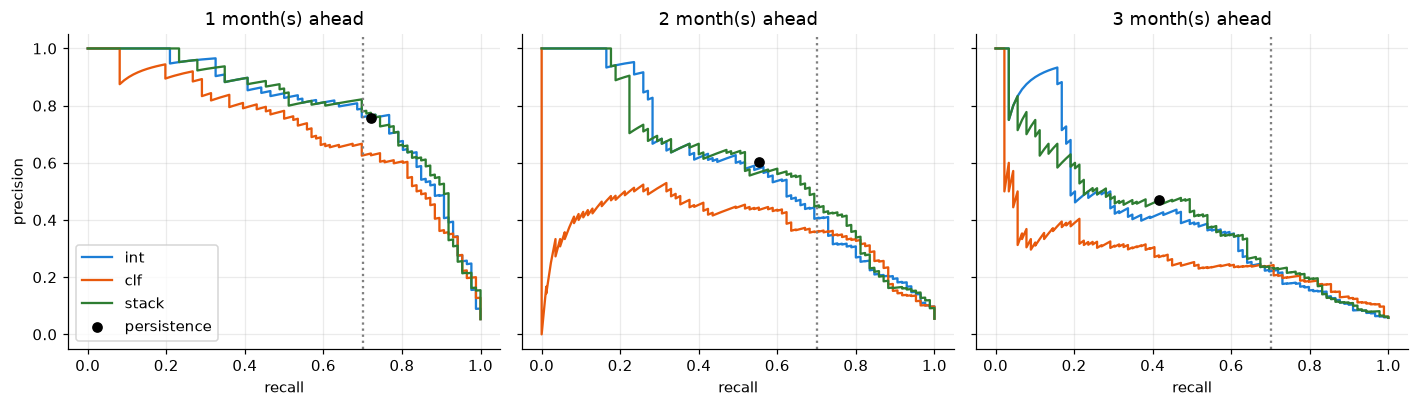

In [3]:
from sklearn.metrics import precision_recall_curve
bc = pd.read_parquet(PROC / "backtest_calibrated.parquet")
bc = bc[bc.event.notna() & bc.alps_pred.notna() & bc.fold.between(*metrics["metric_years"])]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, h in zip(axes, (1, 2, 3)):
    g = bc[bc.h == h]; y = g.event.astype(bool)
    for r, c in [("int", "#1c7ed6"), ("clf", "#e8590c"), ("stack", "#2e7d32")]:
        p, rc, _ = precision_recall_curve(y, g[f"p_alert_{r}"].fillna(0)); ax.plot(rc, p, label=r, color=c)
    pr = ((g.alps_now >= 1) & y).sum() / max((g.alps_now >= 1).sum(), 1); rr = ((g.alps_now >= 1) & y).sum() / y.sum()
    ax.scatter([rr], [pr], color="k", zorder=5, label="persistence"); ax.axvline(0.7, color="grey", ls=":")
    ax.set_title(f"{h} month(s) ahead"); ax.set_xlabel("recall")
axes[0].set_ylabel("precision"); axes[0].legend()
fig.tight_layout(); fig.savefig(FIG / "alert_pr.png", bbox_inches="tight")

## Research question 4: does a forecast-based alert warn earlier than current-month ALPS?

Replays of 2011, 2017 and 2022 with models trained only on earlier years. An episode starts the first month ALPS reaches Alert; the lead is how many months earlier SokoRadar first flagged that market.

In [4]:
pd.DataFrame(metrics["replays"]).round(2)

,year,episodes,warned_earlier,share_warned_earlier,mean_lead_months,flags,flags_followed_by_alert
0,2011,15,13,0.87,1.6,326,235
1,2017,9,9,1.00,2.0,231,127
2,2022,1,1,1.00,3.0,38,29


In [5]:
eps = pd.read_parquet(STORE / "replay_episodes.parquet"); eps

,year,series_id,onset,first_warning,lead_months,peak_alps_6m
0,2011,eldoret-town-uasin-gishu|beans|wholesale,2011-04-01,NaT,0,2.59
1,2011,eldoret-town-uasin-gishu|maize|wholesale,2011-05-01,2011-03-01,2,2.73
2,2011,kisumu|beans|wholesale,2011-05-01,2011-04-01,1,1.74
3,2011,kisumu|maize|wholesale,2011-05-01,2011-04-01,1,3.03
4,2011,kitui|beans|retail,2011-04-01,2011-02-01,2,1.19
5,2011,kitui|maize|retail,2011-05-01,2011-03-01,2,1.78
6,2011,lodwar-turkana|maize|retail,2011-06-01,2011-05-01,1,2.74
7,2011,mandera|maize|retail,2010-12-01,2010-09-01,3,1.72
8,2011,marsabit|maize|retail,2011-08-01,2011-05-01,3,1.73
9,2011,mombasa|beans|wholesale,2011-04-01,2011-03-01,1,1.33


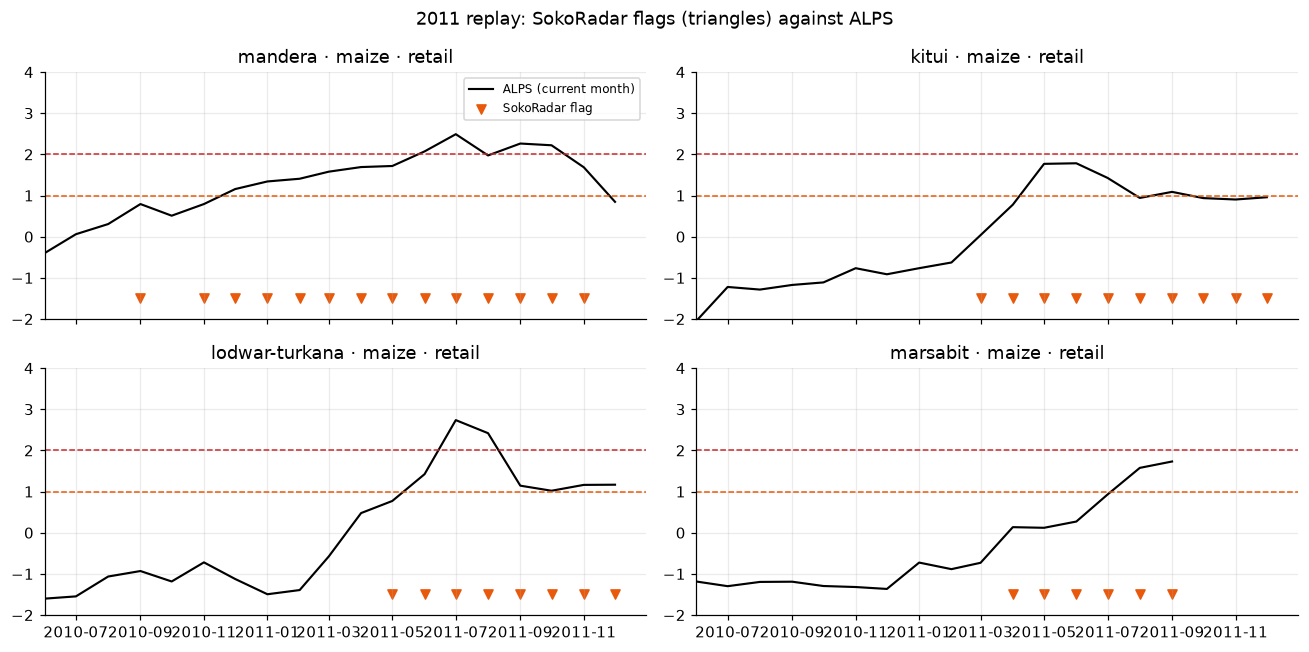

In [6]:
rep = pd.read_parquet(STORE / "replay_monthly.parquet")
alps = pd.read_parquet(PROC / "alps.parquet")
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for ax, sid in zip(axes.flat, ["mandera|maize|retail", "kitui|maize|retail", "lodwar-turkana|maize|retail",
                               "marsabit|maize|retail"]):
    a = alps[(alps.series_id == sid) & alps.month.between("2010-06-01", "2011-12-01")]
    ax.plot(a.month, a.alps, color="k", lw=1.4, label="ALPS (current month)")
    ax.axhline(1, color=PHASE_COLORS["Alert"], ls="--", lw=1); ax.axhline(2, color=PHASE_COLORS["Crisis"], ls="--", lw=1)
    f = rep[(rep.series_id == sid) & rep.flagged & (rep.year == 2011)]
    ax.scatter(f.month, np.full(len(f), -1.5), marker="v", color=PHASE_COLORS["Alert"], label="SokoRadar flag")
    ax.set_title(sid.replace("|", " · ")); ax.set_ylim(-2, 4)
    ax.set_xlim(pd.Timestamp("2010-06-01"), pd.Timestamp("2011-12-31"))
axes[0, 0].legend(fontsize=8); fig.suptitle("2011 replay: SokoRadar flags (triangles) against ALPS")
fig.tight_layout(); fig.savefig(FIG / "replay_2011.png", bbox_inches="tight")

## Research question 3: drivers in pastoral (ASAL) versus high-potential markets

Mean absolute SHAP value of the LightGBM forecaster, summed by driver family, as a share of the total.

h                  1                        2                        3                   
asal            arid non-ASAL semi-arid  arid non-ASAL semi-arid  arid non-ASAL semi-arid
family                                                                                   
macro            6.3      6.4       6.1  11.5     10.3      10.1  11.5      9.9      10.7
market_network  20.5     26.4      23.3  20.9     18.2      19.9  19.5     17.0      17.3
market_profile   2.6      2.7       1.3   1.8      1.5       1.8   1.2      1.1       1.3
policy           0.0      0.0       0.0   0.0      0.0       0.0   0.0      0.0       0.0
price_level      2.9      3.3       3.1   3.7      5.3       4.5   5.6      6.9       6.0
price_momentum  33.8     25.2      29.4  24.7     21.1      22.8  23.1     21.3      23.8
rainfall        12.4     10.5      11.2  14.2     13.6      13.8  13.6     11.5      12.5
seasonality     11.6     16.1      14.1  14.5     19.1      15.8  16.0     20.3      15.9
vegetation       9.9      9.3      11.5   8.6     10.8      11.4   9.6     12.0      12.5

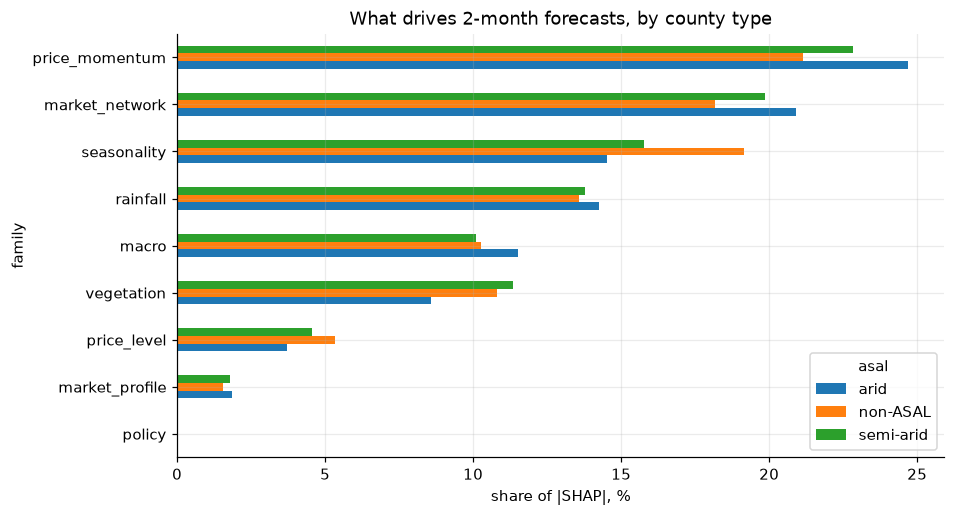

In [7]:
sh = pd.read_parquet(STORE / "shap_summary.parquet")
piv = sh[sh.h == 2].pivot(index="family", columns="asal", values="share").sort_values("arid")
ax = (100 * piv).plot.barh(figsize=(9, 5)); ax.set_xlabel("share of |SHAP|, %")
ax.set_title("What drives 2-month forecasts, by county type"); plt.savefig(FIG / "shap_by_asal.png", bbox_inches="tight")
(100 * sh.pivot_table(index="family", columns=["h", "asal"], values="share")).round(1)

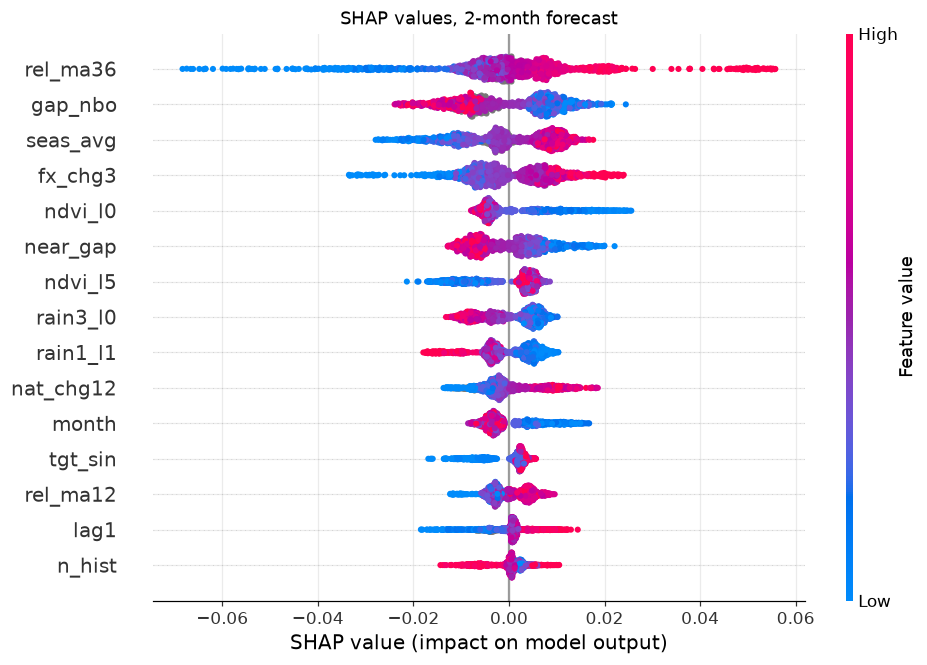

In [8]:
import shap, joblib
from sokoradar.features import design, origins
bundle = joblib.load(ROOT / "models/production.joblib")
m = bundle["forecasters"]["lgbm"]
panel = pd.read_parquet(PROC / "panel.parquet"); org = origins(panel)
X = design(org[org.tgt_h2.notna()].sample(1500, random_state=0), 2, m.features)
sv = shap.TreeExplainer(m.models[(2, "point")]).shap_values(X)
shap.summary_plot(sv, X, max_display=15, show=False, plot_size=(9, 6))
plt.title("SHAP values, 2-month forecast"); plt.savefig(FIG / "shap_beeswarm.png", bbox_inches="tight")

## Explanations as users see them

In [9]:
f = pd.read_parquet(STORE / "forecasts.parquet")
live = f[f.live & (f.h == 1)]
for r in live.sort_values("p_alert", ascending=False).head(4).itertuples():
    print(f"{r.market} · {r.commodity} · {r.target_month:%b %Y}: {r.price_fcst:.0f} KES/kg ({r.phase})")
    print("  EN:", r.why_en); print("  SW:", r.why_sw, "\n")

Eldoret town (Uasin Gishu) · maize · Sep 2026: 69 KES/kg (Alert)
  EN: Main reasons: maize here costs 50% more than the Nairobi wholesale price (pushing prices down); recent price movements (pushing prices down); prices usually fall about 5% between Aug and Sep (pushing prices down).
  SW: Sababu kuu: bei hapa iko juu kwa 50% kuliko bei ya jumla Nairobi (inapunguza bei); mwenendo wa bei (inapunguza bei); kwa kawaida bei hushuka kati ya Agosti na Septemba (inapunguza bei). 

Kakuma 3 · goat_meat · Sep 2026: 792 KES/kg (Normal)
  EN: Main reasons: below-normal rains over the last 3 months (27% of normal) (pushing prices up); prices have fallen 1% over the last 3 months (pushing prices down); prices usually rise about 4% between Aug and Sep (pushing prices down).
  SW: Sababu kuu: mvua chini ya kawaida miezi 3 iliyopita (27%) (inaongeza bei); bei imeshuka 1% miezi 3 iliyopita (inapunguza bei); kwa kawaida bei hupanda kati ya Agosti na Septemba (inapunguza bei). 

IFO (Daadab) · goat_meat 

## What-if rainfall

Live forecasts re-scored with the last three months' rainfall set to a share of normal. This is a sensitivity test of the model, not a weather forecast.

In [10]:
from sokoradar.scenario import sensitivity
sens = sensitivity((40, 60, 80, 100, 130, 160, 200)); sens

,rain_pct,alert_or_crisis,mean_price_shift_pct
0,40,4,0.082778
1,60,4,-0.298175
2,80,4,-0.366349
3,100,4,-0.601746
4,130,3,-0.938730
5,160,3,-1.087619
6,200,3,-1.185794


## IPC context

The latest IPC analysis on HDX, for the validation question \"do price alerts lead IPC deterioration?\" — county-level IPC history is needed for a proper test (future work).

In [11]:
ipc = pd.read_csv(ROOT / "data/raw/ipc_ken_level1_long_latest.csv")
ipc[ipc.Phase.isin(["3+", "4"])][["Date of analysis", "Level 1", "Validity period", "Phase", "Number"]]

,Date of analysis,Level 1,Validity period,Phase,Number
1,Jul 2026,Arid and Semi-Arid Lands (ASALs),current,3+,2735210
5,Jul 2026,Arid and Semi-Arid Lands (ASALs),current,4,347850
8,Jul 2026,Arid and Semi-Arid Lands (ASALs),first projection,3+,2118275
12,Jul 2026,Arid and Semi-Arid Lands (ASALs),first projection,4,262300
15,Jul 2026,Refugees,current,3+,351449
19,Jul 2026,Refugees,current,4,77887
22,Jul 2026,Refugees,first projection,3+,430277
26,Jul 2026,Refugees,first projection,4,131466
